In [1]:
from WF4Py import waveforms as WF;
from WF4Py import WFutils as utils;

import numpy as np
from astropy.cosmology import Planck18

import pycbc.conversions as cvs;
import pycbc.waveform as pycbc_wf;
import pycbc.types as pycbc_tps;

import time
import sys
import os

import matplotlib.pyplot as plt
from matplotlib import gridspec
from matplotlib import rc
rc('text', usetex=False)


ourcodenameString = 'WF4Py'


/workspace/minconda3/envs/preload/lib/python3.9/site-packages/pycbc/types/array.py:36: UserWarning: Wswiglal-redir-stdio:

SWIGLAL standard output/error redirection is enabled in IPython.
This may lead to performance penalties. To disable locally, use:

with lal.no_swig_redirect_standard_output_error():
    ...

To disable globally, use:

lal.swig_redirect_standard_output_error(False)

Note however that this will likely lead to error messages from
LAL functions being either misdirected or lost when called from
Jupyter notebooks.

To suppress this warning, use:

import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")
import lal

  import lal as _lal
/workspace/minconda3/envs/preload/lib/python3.9/site-packages/pykerr/qnm.py:2: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  im

In [3]:
m1 = np.array([33.])
m2 = np.array([12.])

events = dict(
    Mc =  np.array(cvs.mchirp_from_mass1_mass2(m1, m2)),
    eta = np.array(cvs.eta_from_mass1_mass2(m1, m2)   ),
    # chi1x = np.array([0.2  ]),
    # chi1y = np.array([-0.3 ]),
    chi1z = np.array([0.8  ]),
    # chi2x = np.array([-0.37]),
    # chi2y = np.array([-0.02]),
    chi2z = np.array([0.57 ]),
    dL    = np.array([0.137 ]),
    iota = np.array([0.])
)

events_dchi3 = events | {"dchi3": -394.14586894}

In [4]:
tmpWF = WF.IMRPhenomXAS(InsPhaseVersion=104, IntPhaseVersion=105, IntAmpVersion=104)

fcut = tmpWF.fcut(**events)
fminarr = np.full(fcut.shape, 5)
fgrids = np.geomspace(fminarr, fcut, num=int(1000))

In [6]:
fcut, fminarr, fgrids[:10]

(array([1353.50295678]),
 array([5]),
 array([[5.        ],
        [5.02811183],
        [5.05638172],
        [5.08481055],
        [5.11339922],
        [5.14214862],
        [5.17105967],
        [5.20013326],
        [5.22937032],
        [5.25877175]]))

In [5]:
myampl = tmpWF.Ampl(fgrids, **events)
myphase = tmpWF.Phi(fgrids, **events)


In [9]:
# myphase_dchi3 = tmpWF.Phi(fgrids, **events_dchi3)
# myphase_dchi3 = tmpWF.Phi(fgrids, ** events|{"dchi3":-30})
# myphase_dchi3 = tmpWF.Phi(fgrids, ** events|{"dchi6":15.96367509})
myphase_dchi3 = tmpWF.Phi(fgrids, ** events|{"dchi6L":-1.1547+10})

dchi6L, derivative:
[-66.82607401]
[-877.12927168]
dchi6L, derivative:
[-66.82607401]
[-877.12927168]


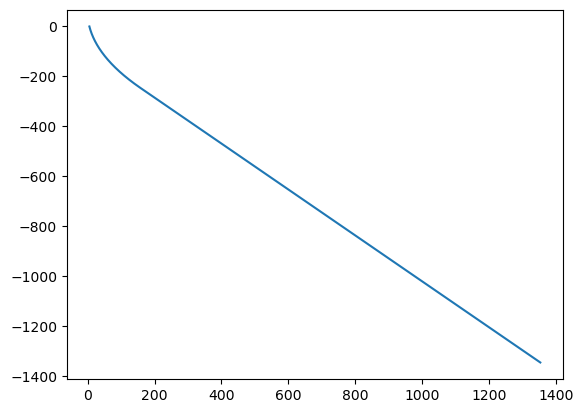

In [10]:
plt.plot(fgrids, myphase_dchi3 - myphase)

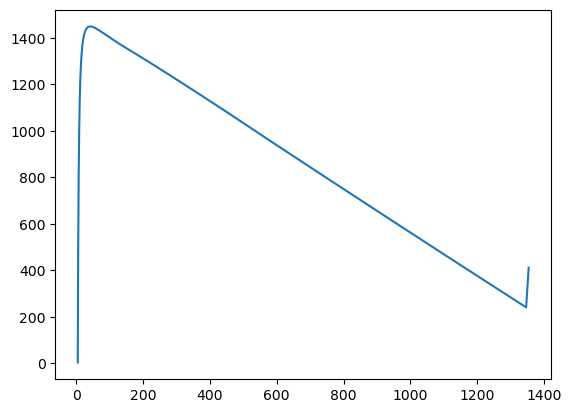

In [11]:
plt.plot(fgrids, myphase_dchi3)

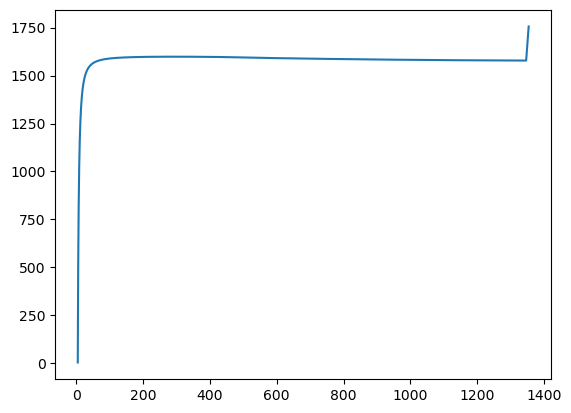

In [8]:
plt.plot(fgrids, myphase)

NameError: name 'myphase_dchi3' is not defined

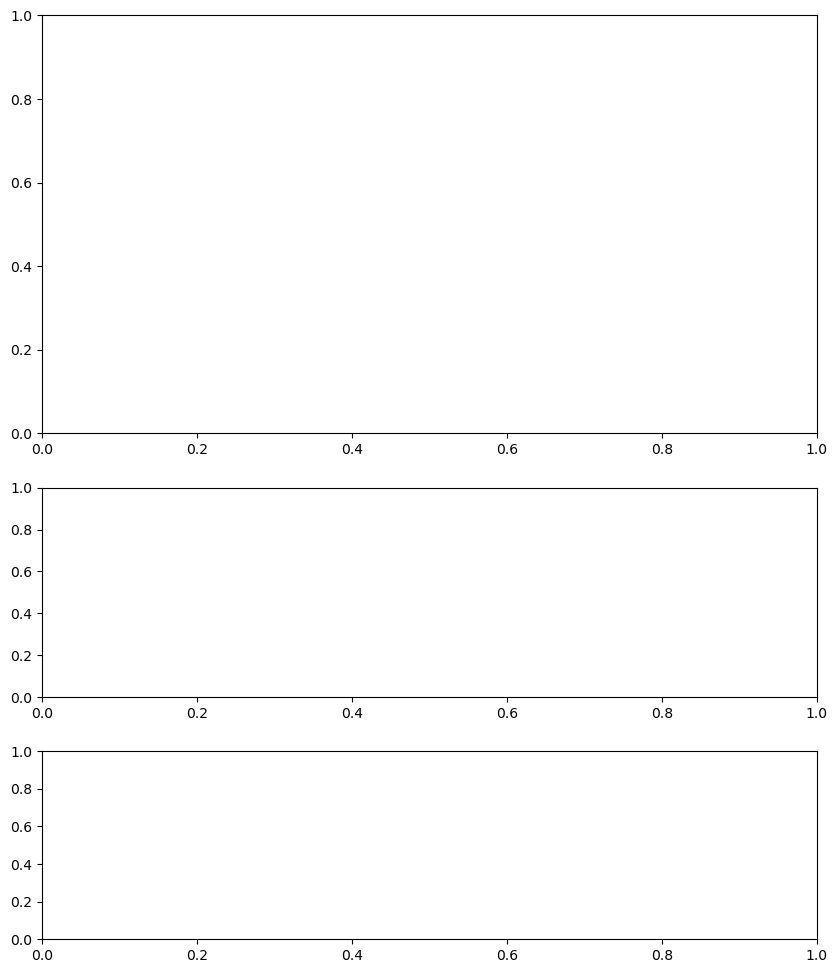

In [6]:
fig = plt.figure(figsize=(10,12))
gs = gridspec.GridSpec(3,1,height_ratios=[2,1,.9])
ax1 = plt.subplot(gs[0])
ax2 = plt.subplot(gs[1], sharex=ax1)
ax3 = plt.subplot(gs[2], sharex=ax1)
# ax1.plot(fgrids, PyCBCwfAmpl, 'C1', label=r'$\texttt{LAL}$', alpha=.35, linewidth=6.)
# ax1.plot(fgrids, myampl, 'C0', label=r'$\texttt{%s}$'%ourcodenameString)
ax1.plot(fgrids, myphase_dchi3, 'C1', label=r'LAL', alpha=.35, linewidth=6.)
ax1.plot(fgrids, myphase, 'C0', label=ourcodenameString)
ax1.set_yscale('log')
# ax1.set_ylabel(r'$A_+ \, ({\rm Hz}^{-1})$',fontsize=20)
ax1.set_ylabel(r'A_+ \, (Hz^-1)',fontsize=20)
ax1.grid()
ax2.plot(fgrids, myphase_dchi3.real, 'C1', alpha=.35, linewidth=6.)
ax2.plot(fgrids[:,0], np.cos(myphase[:,0]), 'C0',)
# ax2.set_ylabel(r'$\cos(\Psi_{+})$', fontsize=20)
# plt.xlabel(r'$f \, (\rm Hz)$', fontsize=20)
ax2.set_ylabel(r'cos(Psi^+)', fontsize=20)
plt.xlabel(r'f \, (Hz)', fontsize=20)
yticks = ax2.yaxis.get_major_ticks()
yticks[-1].label1.set_visible(False)
ax3.plot(fgrids[:,0], abs(1.-(myphase[:,0])/(myphase_dchi3)), '.', color='C2', ms=3)
# ax3.set_ylabel(r'$\rm res$', fontsize=20)
ax3.set_ylabel(r'res', fontsize=20)
ax1.set_xscale('log')
ax3.set_yscale('log')

plt.subplots_adjust(hspace=0.)

handles, labels = ax1.get_legend_handles_labels()
ax1.legend(handles[::-1], labels[::-1], loc='lower left', fontsize=20)

ax1.tick_params(axis='both', which='major', labelsize=14)
ax1.tick_params(axis='both', which='minor', labelsize=14)
ax2.tick_params(axis='both', which='major', labelsize=14)
ax2.tick_params(axis='both', which='minor', labelsize=14)
ax3.tick_params(axis='both', which='major', labelsize=14)
ax3.tick_params(axis='both', which='minor', labelsize=14)

plt.xlim(min(fgrids), max(fgrids))
ax1.grid(True, which='both', ls='dotted', linewidth='0.8', alpha=.8)
ax2.grid(True, which='both', ls='dotted', linewidth='0.8', alpha=.8)
ax3.grid(True, which='both', ls='dotted', linewidth='0.8', alpha=.8)

# ax1.set_title(r"{$\bf \texttt{IMRPhenomD}$}", fontsize=25)
ax1.set_title(r"IMRPhenomXAS", fontsize=25)

plt.show()

In [6]:

hp, hc = pycbc_wf.get_fd_waveform_sequence(approximant='IMRPhenomXAS',
                                                    mass1=m1,
                                                    mass2=m2,
                                                    spin1z=events['chi1z'],
                                                    spin2z=events['chi2z'],
                                                    sample_points = pycbc_tps.array.Array(fgrids[:,0]),
                                                    distance=events['dL']*1000.,
                                                    mode_array = [[2,2]])

PyCBCwfAmpl = np.array(abs(hp))
PyCBCwfPhase = np.unwrap(np.angle(hp))

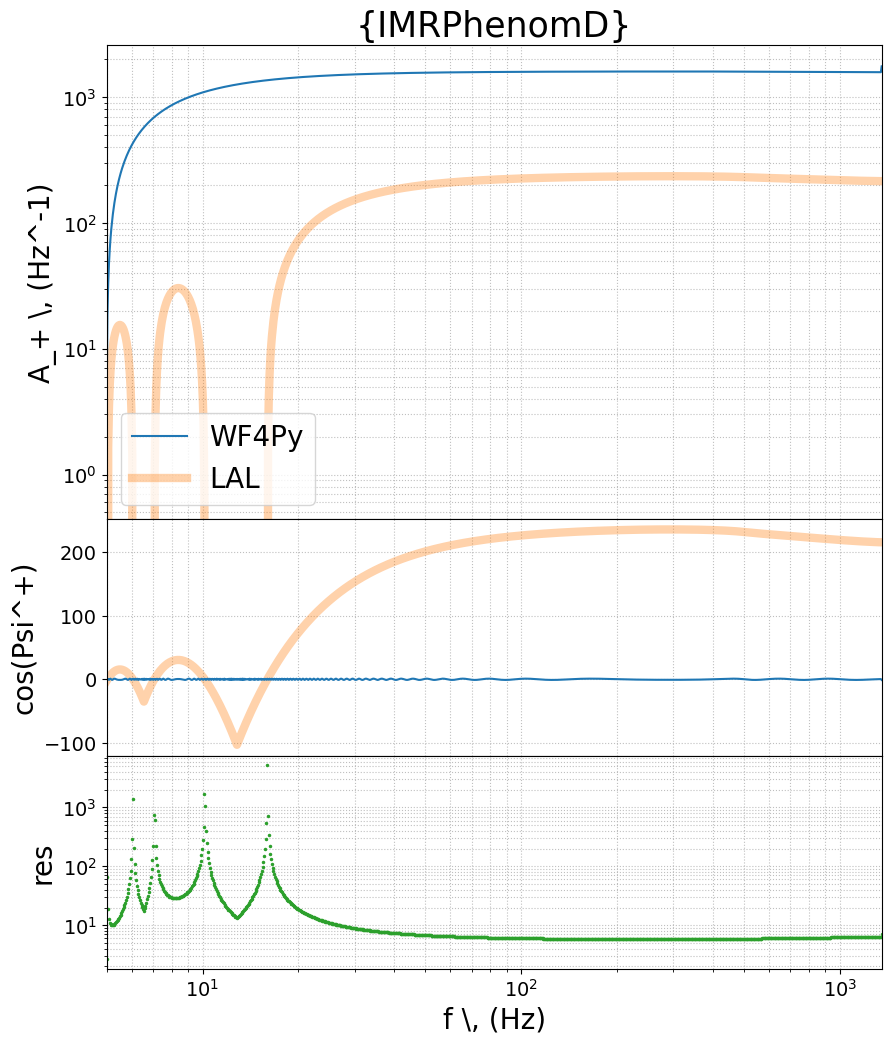

In [ ]:
fig = plt.figure(figsize=(10,12))
gs = gridspec.GridSpec(3,1,height_ratios=[2,1,.9])
ax1 = plt.subplot(gs[0])
ax2 = plt.subplot(gs[1], sharex=ax1)
ax3 = plt.subplot(gs[2], sharex=ax1)
# ax1.plot(fgrids, PyCBCwfAmpl, 'C1', label=r'$\texttt{LAL}$', alpha=.35, linewidth=6.)
# ax1.plot(fgrids, myampl, 'C0', label=r'$\texttt{%s}$'%ourcodenameString)
ax1.plot(fgrids, PyCBCwfPhase, 'C1', label=r'LAL', alpha=.35, linewidth=6.)
ax1.plot(fgrids, myphase, 'C0', label=ourcodenameString)
ax1.set_yscale('log')
# ax1.set_ylabel(r'$A_+ \, ({\rm Hz}^{-1})$',fontsize=20)
ax1.set_ylabel(r'A_+ \, (Hz^-1)',fontsize=20)
ax1.grid()
ax2.plot(fgrids, PyCBCwfPhase.real, 'C1', alpha=.35, linewidth=6.)
ax2.plot(fgrids[:,0], np.cos(myphase[:,0]), 'C0',)
# ax2.set_ylabel(r'$\cos(\Psi_{+})$', fontsize=20)
# plt.xlabel(r'$f \, (\rm Hz)$', fontsize=20)
ax2.set_ylabel(r'cos(Psi^+)', fontsize=20)
plt.xlabel(r'f \, (Hz)', fontsize=20)
yticks = ax2.yaxis.get_major_ticks()
yticks[-1].label1.set_visible(False)
ax3.plot(fgrids[:,0], abs(1.-(myphase[:,0])/(PyCBCwfPhase)), '.', color='C2', ms=3)
# ax3.set_ylabel(r'$\rm res$', fontsize=20)
ax3.set_ylabel(r'res', fontsize=20)
ax1.set_xscale('log')
ax3.set_yscale('log')

plt.subplots_adjust(hspace=0.)

handles, labels = ax1.get_legend_handles_labels()
ax1.legend(handles[::-1], labels[::-1], loc='lower left', fontsize=20)

ax1.tick_params(axis='both', which='major', labelsize=14)
ax1.tick_params(axis='both', which='minor', labelsize=14)
ax2.tick_params(axis='both', which='major', labelsize=14)
ax2.tick_params(axis='both', which='minor', labelsize=14)
ax3.tick_params(axis='both', which='major', labelsize=14)
ax3.tick_params(axis='both', which='minor', labelsize=14)

plt.xlim(min(fgrids), max(fgrids))
ax1.grid(True, which='both', ls='dotted', linewidth='0.8', alpha=.8)
ax2.grid(True, which='both', ls='dotted', linewidth='0.8', alpha=.8)
ax3.grid(True, which='both', ls='dotted', linewidth='0.8', alpha=.8)

# ax1.set_title(r"{$\bf \texttt{IMRPhenomD}$}", fontsize=25)
ax1.set_title(r"IMRPhenomXAS", fontsize=25)

plt.show()

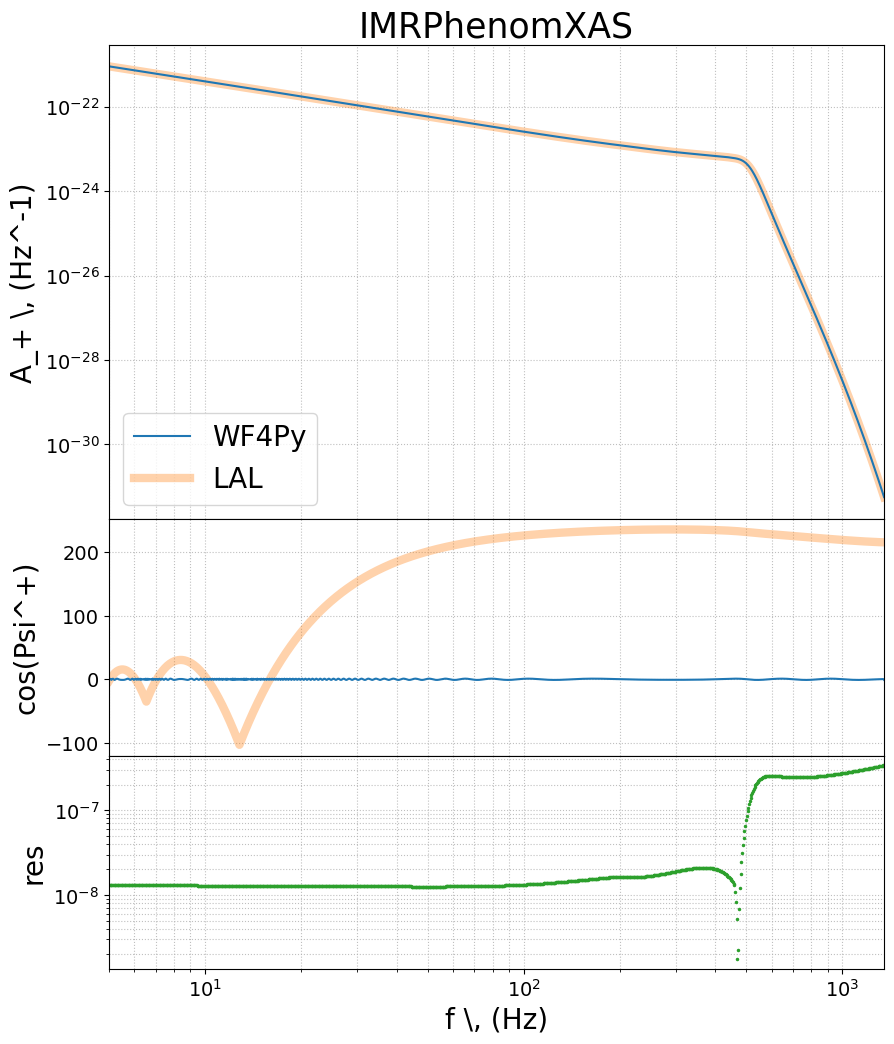

In [8]:
fig = plt.figure(figsize=(10,12))
gs = gridspec.GridSpec(3,1,height_ratios=[2,1,.9])
ax1 = plt.subplot(gs[0])
ax2 = plt.subplot(gs[1], sharex=ax1)
ax3 = plt.subplot(gs[2], sharex=ax1)
# ax1.plot(fgrids, PyCBCwfAmpl, 'C1', label=r'$\texttt{LAL}$', alpha=.35, linewidth=6.)
# ax1.plot(fgrids, myampl, 'C0', label=r'$\texttt{%s}$'%ourcodenameString)
ax1.plot(fgrids, PyCBCwfAmpl, 'C1', label=r'LAL', alpha=.35, linewidth=6.)
ax1.plot(fgrids, myampl, 'C0', label=ourcodenameString)
ax1.set_yscale('log')
# ax1.set_ylabel(r'$A_+ \, ({\rm Hz}^{-1})$',fontsize=20)
ax1.set_ylabel(r'A_+ \, (Hz^-1)',fontsize=20)
ax1.grid()
ax2.plot(fgrids, PyCBCwfPhase.real, 'C1', alpha=.35, linewidth=6.)
ax2.plot(fgrids[:,0], np.cos(myphase[:,0]), 'C0',)
# ax2.set_ylabel(r'$\cos(\Psi_{+})$', fontsize=20)
# plt.xlabel(r'$f \, (\rm Hz)$', fontsize=20)
ax2.set_ylabel(r'cos(Psi^+)', fontsize=20)
plt.xlabel(r'f \, (Hz)', fontsize=20)
yticks = ax2.yaxis.get_major_ticks()
yticks[-1].label1.set_visible(False)
ax3.plot(fgrids[:,0], abs(1.-(myampl[:,0])/(PyCBCwfAmpl)), '.', color='C2', ms=3)
# ax3.set_ylabel(r'$\rm res$', fontsize=20)
ax3.set_ylabel(r'res', fontsize=20)
ax1.set_xscale('log')
ax3.set_yscale('log')

plt.subplots_adjust(hspace=0.)

handles, labels = ax1.get_legend_handles_labels()
ax1.legend(handles[::-1], labels[::-1], loc='lower left', fontsize=20)

ax1.tick_params(axis='both', which='major', labelsize=14)
ax1.tick_params(axis='both', which='minor', labelsize=14)
ax2.tick_params(axis='both', which='major', labelsize=14)
ax2.tick_params(axis='both', which='minor', labelsize=14)
ax3.tick_params(axis='both', which='major', labelsize=14)
ax3.tick_params(axis='both', which='minor', labelsize=14)

plt.xlim(min(fgrids), max(fgrids))
ax1.grid(True, which='both', ls='dotted', linewidth='0.8', alpha=.8)
ax2.grid(True, which='both', ls='dotted', linewidth='0.8', alpha=.8)
ax3.grid(True, which='both', ls='dotted', linewidth='0.8', alpha=.8)

# ax1.set_title(r"{$\bf \texttt{IMRPhenomD}$}", fontsize=25)
ax1.set_title(r"IMRPhenomXAS", fontsize=25)

plt.show()

In [ ]:
from WF4Py import waveforms as WF;
from WF4Py import WFutils as utils;

import numpy as np
from astropy.cosmology import Planck18

import pycbc.conversions as cvs;
import pycbc.waveform as pycbc_wf;
import pycbc.types as pycbc_tps;

import time
import sys
import os

import matplotlib.pyplot as plt
from matplotlib import gridspec
from matplotlib import rc
rc('text', usetex=False)


ourcodenameString = 'WF4Py'


def get_dchi_modified_IMRPhenomXAS(**kwargs) :
    # // IMPORTANT CHECK: verify that inclination_azimuth is the longitude of ascending nodes

    mass1 = kwargs["mass1"]
    mass2 = kwargs["mass2"]
    chi1z = kwargs["spin1z"]
    chi2z = kwargs["spin2z"]
    dL = kwargs["distance"]

    phi0 = kwargs["coa_phase"]
    # kwargs["long_asc_nodes"]
    # kwargs["mean_per_ano"]

    events = dict(
        Mc =  np.array([cvs.mchirp_from_mass1_mass2(mass1, mass2)]),
        eta = np.array([cvs.eta_from_mass1_mass2(mass1, mass2)   ]),
        chi1z = np.array([ chi1z ]),
        chi2z = np.array([ chi2z ]),
        dL    = np.array([ dL/1000. ])
    )

    print(events)

    if "dchi0" in kwargs:
        events["dchi0"] = kwargs["dchi0"]
    elif "dchi1" in kwargs:
        events["dchi1"] = kwargs["dchi1"]
    elif "dchi2" in kwargs:
        events["dchi2"] = kwargs["dchi2"]
    elif "dchi3" in kwargs:
        events["dchi3"] = kwargs["dchi3"]
    elif "dchi4" in kwargs:
        events["dchi4"] = kwargs["dchi4"]
    elif "dchi5L" in kwargs:
        events["dchi5L"] = kwargs["dchi5L"]
    elif "dchi5" in kwargs:
        events["dchi5"] = kwargs["dchi5"]
    elif "dchi6" in kwargs:
        events["dchi6"] = kwargs["dchi6"]
    elif "dchi6L" in kwargs:
        events["dchi6L"] = kwargs["dchi6L"]
    elif "dchi7" in kwargs:
        events["dchi7"] = kwargs["dchi7"]
    elif "dchi8" in kwargs:
        events["dchi8"] = kwargs["dchi8"]
    elif "dchi8L" in kwargs:
        events["dchi8L"] = kwargs["dchi8L"]
    else:
        pass

    tmpWF = WF.IMRPhenomXAS(InsPhaseVersion=104, IntPhaseVersion=105, IntAmpVersion=104)

    # fcut = kwargs["f_final"] if "f_final" in kwargs else tmpWF.fcut(**events)
    fcut = tmpWF.fcut(**events)
    fminarr = np.full(fcut.shape, kwargs["f_lower"])
    delta_f = kwargs["delta_f"]
    fgrids = np.arange(fminarr, fcut, delta_f)
    fgrids = fgrids.reshape(-1, 1)
    # print(f"fcut: {fcut.shape}")
    # print(fminarr)
    # print(fgrids)

    xas_ampl = tmpWF.Ampl(fgrids, **events) + 2*phi0
    xas_phase = tmpWF.Phi(fgrids, **events)

    print(f"xas_phase: {xas_phase[:10]}")

    def htilde22(phase, ampl) :
        return ampl * np.exp(-1j*phase)

    iota = kwargs["inclination"]

    def hphc(phase, ampl, iota) :
        cfac = np.cos(iota)
        Ylmfactor = 2.0 * np.sqrt(5.0 / (64.0 * np.pi)) * np.exp(-1j * 2 * (np.pi/2))
        pfac = 0.5 * (1. + cfac*cfac)
        hp = htilde22(phase, ampl)
        hc = -1j * cfac * hp * Ylmfactor
        hp *= pfac*Ylmfactor

        return hp, hc
    
    hp, hc = hphc(xas_phase, xas_ampl, iota)

    return hp, hc

In [39]:
events = dict(
    mass1 = 33,
    mass2 = 12,
    spin1z = 0.8,
    spin2z = 0.57,
    distance = 0.137,
    inclination = 0.,
    coa_phase = 0,

    f_lower = 5,
    delta_f = 1.16,
    f_final = 2048,
)

# events = dict(
#     Mc =  np.array(cvs.mchirp_from_mass1_mass2(m1, m2)),
#     eta = np.array(cvs.eta_from_mass1_mass2(m1, m2)   ),
#     # chi1x = np.array([0.2  ]),
#     # chi1y = np.array([-0.3 ]),
#     chi1z = np.array([0.8  ]),
#     # chi2x = np.array([-0.37]),
#     # chi2y = np.array([-0.02]),
#     chi2z = np.array([0.57 ]),
#     dL    = np.array([0.137 ]),
#     iota = np.array([0.])
# )

In [40]:
hp, hc = get_dchi_modified_IMRPhenomXAS(**events)

{'Mc': array([16.90342102]), 'eta': array([0.19555556]), 'chi1z': array([0.8]), 'chi2z': array([0.57]), 'dL': array([0.000137])}
fcut: (1,)
[5]
[[   5.  ]
 [   6.16]
 [   7.32]
 ...
 [1350.6 ]
 [1351.76]
 [1352.92]]
xas_phase: [[   3.92699082]
 [ 467.26984913]
 [ 746.94602259]
 [ 930.15716051]
 [1057.44791732]
 [1149.89867367]
 [1219.41442302]
 [1273.16134161]
 [1315.67788673]
 [1349.95997054]]


/tmp/ipykernel_444027/3269818913.py:80: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  fgrids = np.arange(fminarr, fcut, delta_f)


/workspace/minconda3/envs/preload/lib/python3.9/site-packages/matplotlib/cbook.py:1762: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/workspace/minconda3/envs/preload/lib/python3.9/site-packages/matplotlib/cbook.py:1398: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


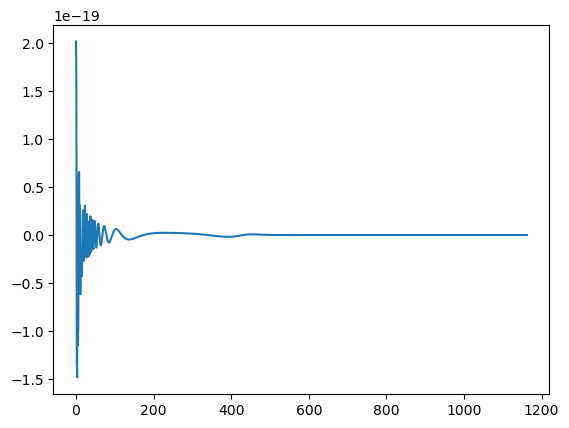

In [41]:
import matplotlib.pyplot as pp

pp.plot(hp)

In [3]:
events = dict(
    mass1 = 33,
    mass2 = 12,
    spin1z = 0.8,
    spin2z = 0.57,
    distance = 0.137,
    inclination = 0,
    coa_phase = 0,

    f_lower = 5,
    delta_f = 1.16,
    f_final = 2048,
)

fcut = tmpWF.fcut(**events)
fminarr = np.full(fcut.shape, events["f_lower"])
delta_f = events["delta_f"]
fgrids = np.arange(fminarr, fcut, delta_f)
fgrids = fgrids.reshape(-1, 1)

hp1, hc1 = pycbc_wf.get_fd_waveform_sequence(approximant='IMRPhenomXAS',
                                                    mass1=events['mass1'],
                                                    mass2=events['mass2'],
                                                    spin1z=events['spin1z'],
                                                    spin2z=events['spin2z'],
                                                    sample_points = pycbc_tps.array.Array(fgrids[:,0]),
                                                    distance=events['distance'],
                                                    # mode_array = [[2,2]],
                                                    inclination=events['inclination']
                                                    )

NameError: name 'tmpWF' is not defined

/workspace/minconda3/envs/preload/lib/python3.9/site-packages/matplotlib/cbook.py:1762: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/workspace/minconda3/envs/preload/lib/python3.9/site-packages/matplotlib/cbook.py:1398: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


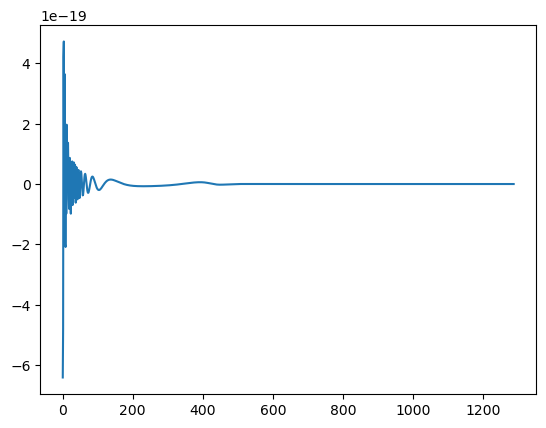

In [103]:
pp.plot(hp1)

In [1]:
def get_dchi_modified_IMRPhenomXAS(**kwargs) :
    # // IMPORTANT CHECK: verify that inclination_azimuth is the longitude of ascending nodes

    mass1 = kwargs["mass1"]
    mass2 = kwargs["mass2"]
    chi1z = kwargs["spin1z"]
    chi2z = kwargs["spin2z"]
    dL = kwargs["distance"]

    phi0 = kwargs["coa_phase"]
    # kwargs["long_asc_nodes"]
    # kwargs["mean_per_ano"]

    events = dict(
        Mc =  np.array([cvs.mchirp_from_mass1_mass2(mass1, mass2)]),
        eta = np.array([cvs.eta_from_mass1_mass2(mass1, mass2)   ]),
        chi1z = np.array([ chi1z ]),
        chi2z = np.array([ chi2z ]),
        dL    = np.array([ dL/1000. ])
    )

    print(events)

    if "dchi0" in kwargs:
        events["dchi0"] = kwargs["dchi0"]
    elif "dchi1" in kwargs:
        events["dchi1"] = kwargs["dchi1"]
    elif "dchi2" in kwargs:
        events["dchi2"] = kwargs["dchi2"]
    elif "dchi3" in kwargs:
        events["dchi3"] = kwargs["dchi3"]
    elif "dchi4" in kwargs:
        events["dchi4"] = kwargs["dchi4"]
    elif "dchi5L" in kwargs:
        events["dchi5L"] = kwargs["dchi5L"]
    elif "dchi5" in kwargs:
        events["dchi5"] = kwargs["dchi5"]
    elif "dchi6" in kwargs:
        events["dchi6"] = kwargs["dchi6"]
    elif "dchi6L" in kwargs:
        events["dchi6L"] = kwargs["dchi6L"]
    elif "dchi7" in kwargs:
        events["dchi7"] = kwargs["dchi7"]
    elif "dchi8" in kwargs:
        events["dchi8"] = kwargs["dchi8"]
    elif "dchi8L" in kwargs:
        events["dchi8L"] = kwargs["dchi8L"]
    else:
        pass

    tmpWF = WF.IMRPhenomXAS(InsPhaseVersion=104, IntPhaseVersion=105, IntAmpVersion=104)

    fcut = kwargs["f_final"] if "f_final" in kwargs else tmpWF.fcut(**events)
    # fcut = tmpWF.fcut(**events)
    fminarr = np.full(fcut.shape, kwargs["f_lower"])
    delta_f = kwargs["delta_f"]
    fgrids = np.arange(fminarr, fcut, delta_f)
    fgrids = fgrids.reshape(-1, 1)

    xas_ampl = tmpWF.Ampl(fgrids, **events) + 2*phi0
    xas_phase22 = tmpWF.Phi(fgrids, **events)

    # def htilde22(phase, ampl) :
    #     return ampl * np.exp(-1j*phase)
    # h22 = htilde22(xas_phase22, xas_ampl)

    # h2_2 = np.conj(h22)

    # xas_phase2_2 = np.unwrap(np.angle(h2_2))

    iota = kwargs["inclination"]


    # return utils.Add_Higher_Modes(Ampl={"22": xas_ampl, "2-2": xas_ampl}, Phi={"22": xas_phase22, "2-2": xas_phase2_2}, iota=iota)
    return utils.Add_Higher_Modes(Ampl={"22": xas_ampl}, Phi={"22": xas_phase22}, iota=iota)

In [2]:
events = dict(
    mass1 = 33,
    mass2 = 12,
    spin1z = 0.8,
    spin2z = 0.57,
    distance = 0.137,
    inclination = 0,
    coa_phase = 0,

    f_lower = 5,
    delta_f = 1.16,
    f_final = 2048,
)
hp2, hc2 = get_dchi_modified_IMRPhenomXAS(**events)

NameError: name 'np' is not defined

/workspace/minconda3/envs/preload/lib/python3.9/site-packages/matplotlib/cbook.py:1762: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/workspace/minconda3/envs/preload/lib/python3.9/site-packages/matplotlib/cbook.py:1398: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


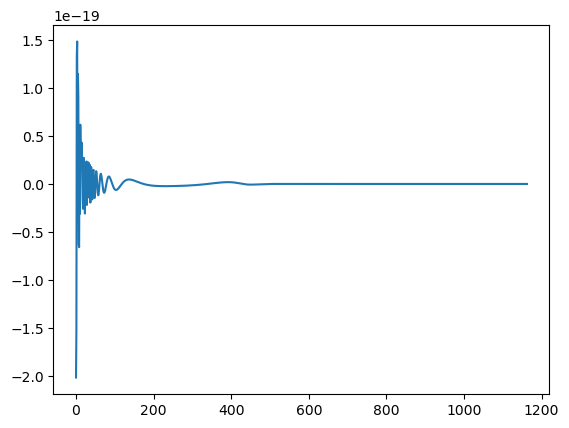

In [113]:
pp.plot(hp2)

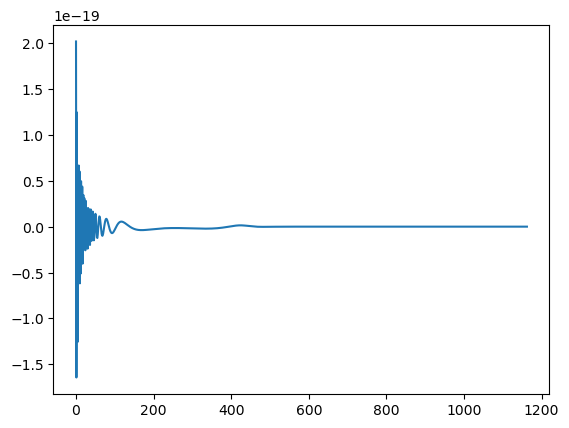

In [106]:
pp.plot(hc2)